# Continuous-relaxation gap figures

This notebook uses `plot_relaxation_gap_choices.py`. It keeps only matched `(instance, p)` runs available for all five models. Every figure is displayed inline and saved as a PDF in `figures/`.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from plot_relaxation_gap_choices import (
    configure_fonts, paired_summary, plot_bar,
    plot_dot, plot_heatmap, plot_lollipop, plot_index,
)

WORKBOOK = ROOT / 'all_v1.xlsx'
FIGURES = ROOT / 'figures'
FIGURES.mkdir(exist_ok=True)
configure_fonts('auto')
summary = paired_summary(WORKBOOK, 'all_v1')
summary.head()

,n,tau,model,runs,gap_percent,relative_deviation,gap_index
0,10,1.5,compact,15,36.941395,0.000000,100.000000
1,10,1.5,PW,15,36.421196,-1.408175,98.591825
2,10,1.5,LR-D,15,35.847981,-2.959863,97.040137
3,10,1.5,LR-A,15,35.926491,-2.747335,97.252665
4,10,1.5,LR-SA,15,36.171481,-2.084151,97.915849


## Coverage of the matched comparisons

The table identifies which values of $n$ have information for each norm. Missing blocks are labeled `N/A` in the corresponding bar plot.

In [2]:
(summary[['n', 'tau', 'runs']]
 .drop_duplicates()
 .pivot(index='n', columns='tau', values='runs')
 .rename(columns={1.5: 'tau=3/2', 2.0: 'tau=2', 3.0: 'tau=3'}))

tau,tau=3/2,tau=2,tau=3
n,,,
10,15.0,15.0,15.0
20,15.0,15.0,15.0
30,1.0,5.0,NaN
40,NaN,4.0,NaN
50,NaN,3.0,NaN


## Three-block bar plots by instance size

Each plot has one block for each $\tau$. Every block contains PW, LR-D, LR-A, and LR-SA deviations from the MISOCO continuous-relaxation gap. Negative values indicate stronger lower bounds than MISOCO.

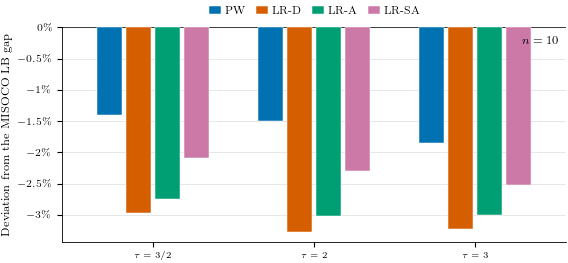

Saved: /Users/vblanco/Library/CloudStorage/OneDrive-UNIVERSIDADDEGRANADA/SDP Clusters Code/figures/relaxation_gap_bar_n10.pdf


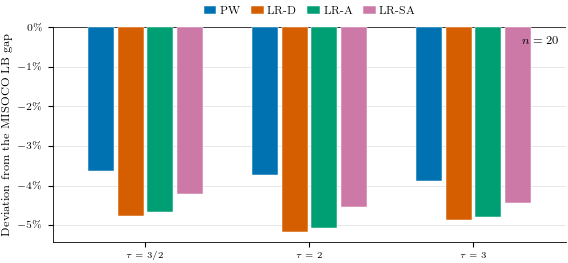

Saved: /Users/vblanco/Library/CloudStorage/OneDrive-UNIVERSIDADDEGRANADA/SDP Clusters Code/figures/relaxation_gap_bar_n20.pdf


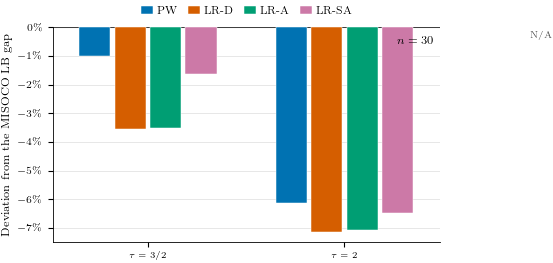

Saved: /Users/vblanco/Library/CloudStorage/OneDrive-UNIVERSIDADDEGRANADA/SDP Clusters Code/figures/relaxation_gap_bar_n30.pdf


/Users/vblanco/Library/CloudStorage/OneDrive-UNIVERSIDADDEGRANADA/SDP Clusters Code/plot_relaxation_gap_choices.py:398: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(pad=0.25)


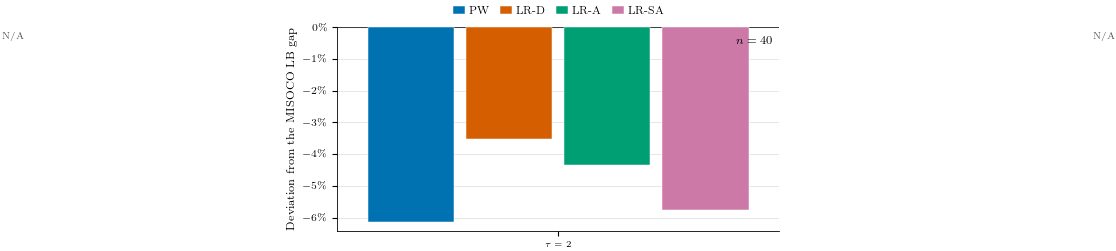

Saved: /Users/vblanco/Library/CloudStorage/OneDrive-UNIVERSIDADDEGRANADA/SDP Clusters Code/figures/relaxation_gap_bar_n40.pdf


/Users/vblanco/Library/CloudStorage/OneDrive-UNIVERSIDADDEGRANADA/SDP Clusters Code/plot_relaxation_gap_choices.py:398: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(pad=0.25)


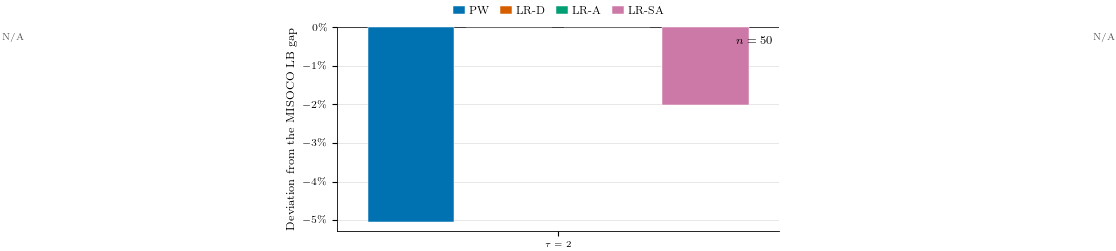

Saved: /Users/vblanco/Library/CloudStorage/OneDrive-UNIVERSIDADDEGRANADA/SDP Clusters Code/figures/relaxation_gap_bar_n50.pdf


In [3]:
for n in sorted(summary['n'].unique()):
    fig = plot_bar(summary, n=int(n))
    destination = FIGURES / f'relaxation_gap_bar_n{int(n)}.pdf'
    fig.savefig(destination, dpi=300)
    plt.show()
    plt.close(fig)
    print(f'Saved: {destination}')

## Aggregate three-block bar plot

This version averages the available size-specific deviations within each norm. Use it only if an aggregate comparison is preferred to a figure for a particular $n$.

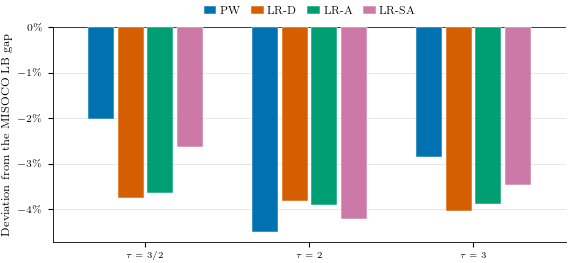

Saved: /Users/vblanco/Library/CloudStorage/OneDrive-UNIVERSIDADDEGRANADA/SDP Clusters Code/figures/relaxation_gap_bar_aggregate.pdf


In [4]:
fig = plot_bar(summary)
destination = FIGURES / 'relaxation_gap_bar_aggregate.pdf'
fig.savefig(destination, dpi=300)
plt.show()
plt.close(fig)
print(f'Saved: {destination}')

## Other layouts

Run this cell to compare the bar plot with the dot, heatmap, lollipop, and indexed alternatives.

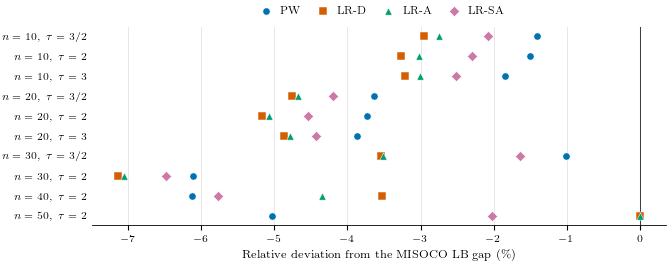

Saved: /Users/vblanco/Library/CloudStorage/OneDrive-UNIVERSIDADDEGRANADA/SDP Clusters Code/figures/relaxation_gap_dot.pdf


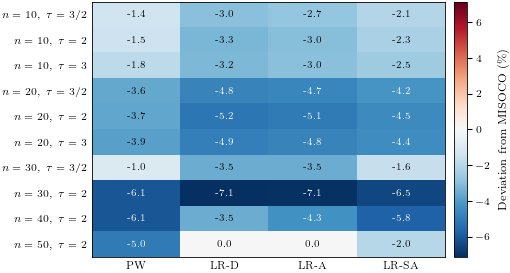

Saved: /Users/vblanco/Library/CloudStorage/OneDrive-UNIVERSIDADDEGRANADA/SDP Clusters Code/figures/relaxation_gap_heatmap.pdf


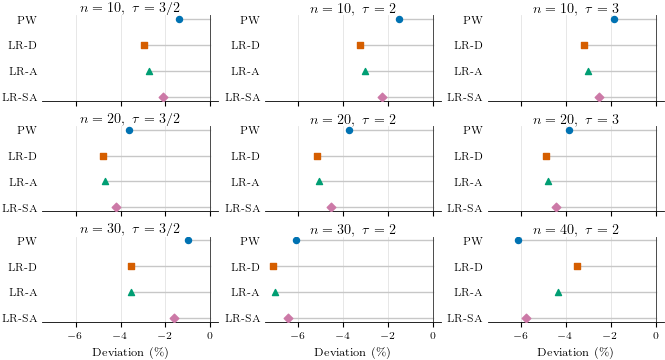

Saved: /Users/vblanco/Library/CloudStorage/OneDrive-UNIVERSIDADDEGRANADA/SDP Clusters Code/figures/relaxation_gap_lollipop.pdf


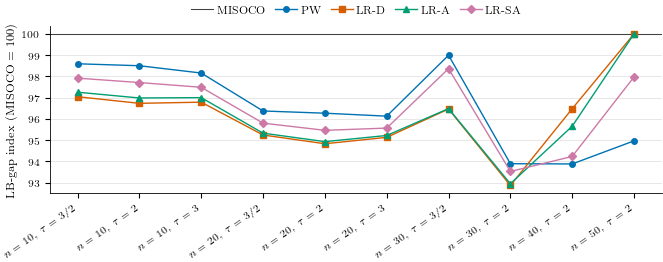

Saved: /Users/vblanco/Library/CloudStorage/OneDrive-UNIVERSIDADDEGRANADA/SDP Clusters Code/figures/relaxation_gap_index.pdf


In [5]:
alternatives = {
    'dot': plot_dot,
    'heatmap': plot_heatmap,
    'lollipop': plot_lollipop,
    'index': plot_index,
}
for name, plotting_function in alternatives.items():
    fig = plotting_function(summary)
    destination = FIGURES / f'relaxation_gap_{name}.pdf'
    fig.savefig(destination, dpi=300)
    plt.show()
    plt.close(fig)
    print(f'Saved: {destination}')